# Лабораторная 2. Цветовая и яркостная коррекция изображений

**Задание**

1. **Цветовая коррекция изображений**
   * коррекция с опорным цветом;
   * «серый мир» (gray world);
   * по виду функции преобразования.

2. **Яркостная коррекция в интерактивном режиме по виду функции преобразования**
   *(необязательное дополнительное задание)*
   * график функции кусочно-линейный;
   * график функции интерполируется сплайном.

3. **Коррекция на основе гистограммы**
   * нормализация гистограммы;
   * эквализация гистограммы.


In [260]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path
from scipy.interpolate import CubicSpline

BASE_DIR = next((p for p in (Path("assets"), Path("lab2/assets")) if p.is_dir()), Path("assets"))
OUT_DIR = BASE_DIR.resolve().parent / "outputs"
OUT_DIR.mkdir(exist_ok=True)


## 1. Цветовая коррекция

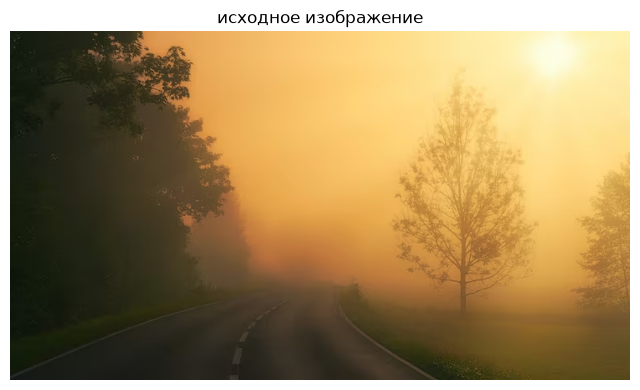

средние по каналам: [149.3 120.1  68.3]


In [261]:
image_path = str(BASE_DIR / "image.jpg")

image = cv2.imread(image_path, cv2.IMREAD_COLOR_RGB)
if image is None:
    raise FileNotFoundError(image_path)

h, w = image.shape[:2]


def channel_means(img):
    """Средние значения по каналам R, G, B."""
    return img.reshape(-1, 3).mean(axis=0)


plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.title("исходное изображение")
plt.axis("off")
plt.show()

print("средние по каналам:", np.round(channel_means(image), 1))


### 1.1. Коррекция с опорным цветом

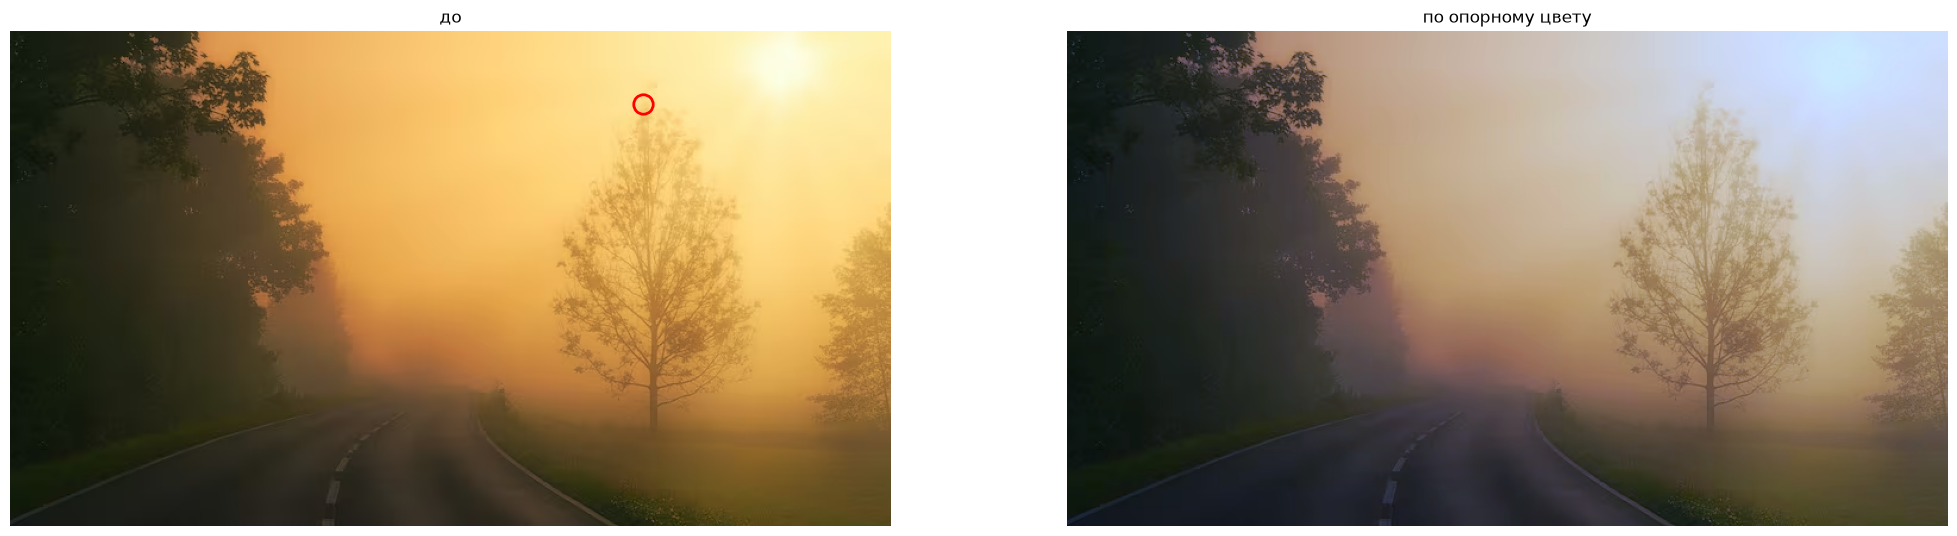

опорная точка : (531, 61)
цвет опоры    : [249.4 217.6 135.1]
коэффициенты  : [0.805 0.922 1.485]
средние после : [119.6 110.3 100.1]


In [262]:
# опорный цвет задаётся вручную: (x, y)
REF_POINT = (531, 61)


def reference_color(img, point, patch=15):
    """Средний цвет окна patch x patch вокруг опорной точки (x, y)."""
    x, y = point
    half = patch // 2
    y0, y1 = max(y - half, 0), min(y + half + 1, img.shape[0])
    x0, x1 = max(x - half, 0), min(x + half + 1, img.shape[1])
    return img[y0:y1, x0:x1].reshape(-1, 3).mean(axis=0)


def correct_by_reference(img, point=REF_POINT, patch=15):
    """Коэффициенты по опорному (белому) участку, заданному вручную."""
    ref_color = reference_color(img, point, patch)
    gains = ref_color.mean() / ref_color
    return np.clip(img * gains, 0, 255).astype(np.uint8), gains, ref_color


corrected_ref, ref_gains, ref_color = correct_by_reference(image)

plt.figure(figsize=(25, 9))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.plot(*REF_POINT, "o", ms=14, mfc="none", mec="red", mew=2)
plt.title("до")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(corrected_ref)
plt.title("по опорному цвету")
plt.axis("off")
plt.show()

print("опорная точка :", REF_POINT)
print("цвет опоры    :", np.round(ref_color, 1))
print("коэффициенты  :", np.round(ref_gains, 3))
print("средние после :", np.round(channel_means(corrected_ref), 1))


### 1.2. «Серый мир» (gray world)


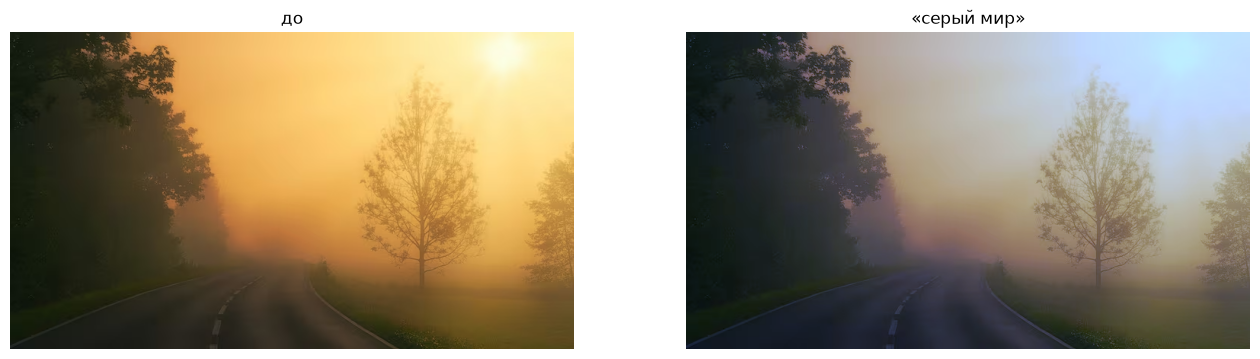

коэффициенты  : [0.754 0.937 1.648]
средние после : [112.1 112.1 109.8]


In [263]:
def gray_world(img):
    m = channel_means(img)
    gains = m.mean() / m
    return np.clip(img * gains, 0, 255).astype(np.uint8), gains


corrected_gw, gw_gains = gray_world(image)

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("до")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(corrected_gw)
plt.title("«серый мир»")
plt.axis("off")
plt.show()

print("коэффициенты  :", np.round(gw_gains, 3))
print("средние после :", np.round(channel_means(corrected_gw), 1))


### 1.3. По виду функции преобразования


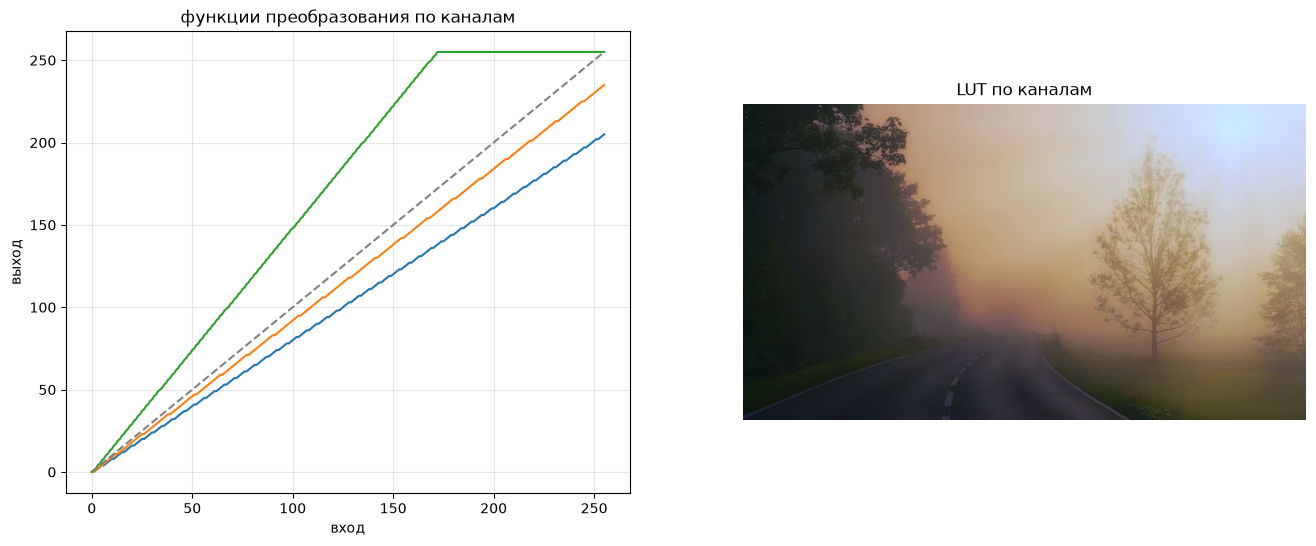

совпадает с коррекцией по опорному цвету: True


In [264]:
def build_lut(func):
    """Таблица преобразования 0..255 -> 0..255."""
    axis = np.arange(256, dtype=np.float64)
    return np.clip(func(axis), 0, 255).astype(np.uint8)


def apply_luts(img, luts):
    """Своя таблица на каждый канал."""
    out = img.copy()
    for i, lut in enumerate(luts):
        out[:, :, i] = cv2.LUT(np.ascontiguousarray(img[:, :, i]), lut)
    return out


lut_linear = [build_lut(lambda v, a=a: v * a) for a in ref_gains]
corrected_lut = apply_luts(image, lut_linear)

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
for ch in lut_linear:
    plt.plot(ch)
plt.plot([0, 255], [0, 255], "--", color="gray")
plt.title("функции преобразования по каналам")
plt.xlabel("вход")
plt.ylabel("выход")
plt.grid(alpha=0.3)
plt.subplot(1, 2, 2)
plt.imshow(corrected_lut)
plt.title("по опорному цвету (через LUT)")
plt.axis("off")
plt.show()

print("совпадает с коррекцией по опорному цвету:", np.array_equal(corrected_lut, corrected_ref))


## 2. Яркостная коррекция по виду функции преобразования

Правим только яркость уже нейтрального изображения. Функция задаётся опорными точками:

* **кусочно-линейная** — точки соединены прямыми;
* **кубический сплайн** — гладкая кривая через те же точки.


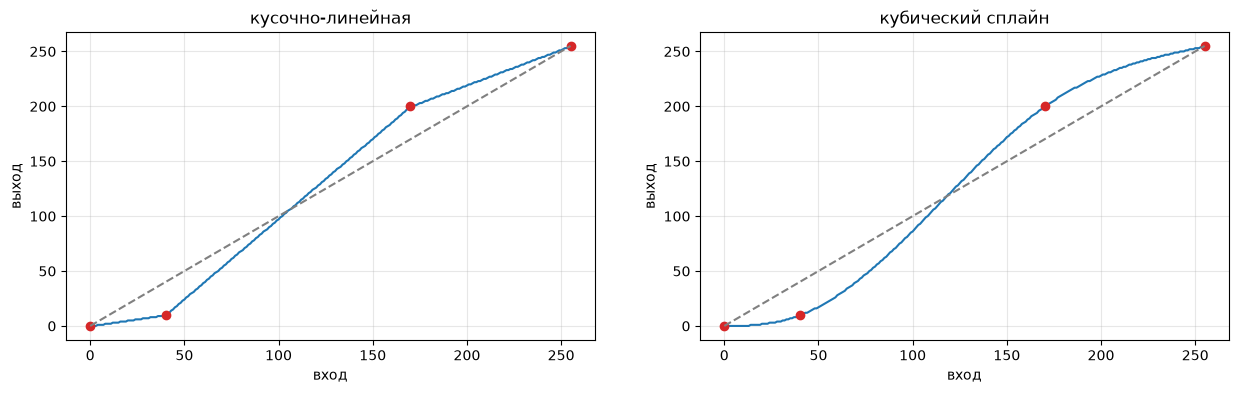

In [265]:
def piecewise_linear_lut(points):
    xs = np.array([p[0] for p in points], dtype=np.float64)
    ys = np.array([p[1] for p in points], dtype=np.float64)
    return build_lut(lambda v: np.interp(v, xs, ys))


def cubic_spline_lut(points):
    """Кубический сплайн (натуральный) через опорные точки -> LUT."""
    xs = np.array([p[0] for p in points], dtype=np.float64)
    ys = np.array([p[1] for p in points], dtype=np.float64)
    spline = CubicSpline(xs, ys, bc_type="natural")
    return build_lut(lambda v: spline(np.clip(v, 0, 255)))


TONE_POINTS = [(0, 0), (40, 10), (170, 200), (255, 255)]

plt.figure(figsize=(15, 4))
for i, (lut, title) in enumerate([(piecewise_linear_lut(TONE_POINTS), "кусочно-линейная"),
                                  (cubic_spline_lut(TONE_POINTS), "кубический сплайн")], start=1):
    plt.subplot(1, 2, i)
    plt.plot(lut)
    plt.plot(*zip(*TONE_POINTS), "o", color="tab:red")
    plt.plot([0, 255], [0, 255], "--", color="gray")
    plt.title(title)
    plt.xlabel("вход")
    plt.ylabel("выход")
    plt.grid(alpha=0.3)
plt.show()


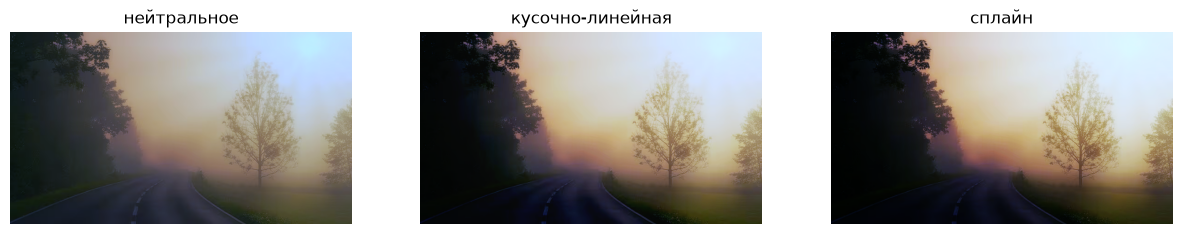

In [266]:
neutral = corrected_gw  

toned_piecewise = apply_luts(neutral, [piecewise_linear_lut(TONE_POINTS)] * 3)
toned_spline = apply_luts(neutral, [cubic_spline_lut(TONE_POINTS)] * 3)

plt.figure(figsize=(15, 6))
for i, (img, title) in enumerate([(neutral, "нейтральное"),
                                  (toned_piecewise, "кусочно-линейная"),
                                  (toned_spline, "сплайн")], start=1):
    plt.subplot(1, 3, i)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")
plt.show()


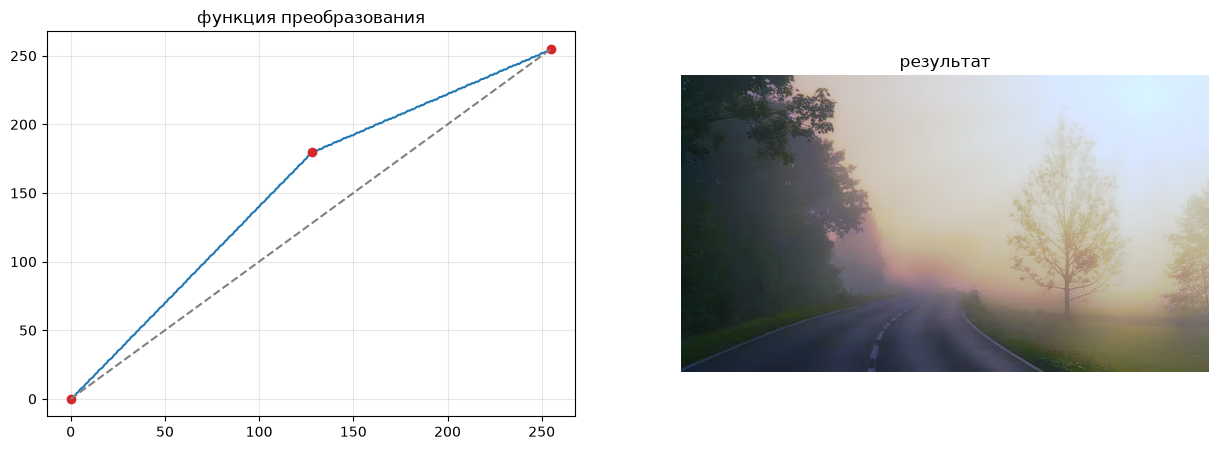

In [267]:
def tone_curve_preview(points=TONE_POINTS, use_spline=False):
    """Функция преобразования + результат её применения."""
    if use_spline:
        lut = cubic_spline_lut(points)
    else:
        lut = piecewise_linear_lut(points)
    result = apply_luts(neutral, [lut] * 3)

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 2, 1)
    plt.plot(lut)
    plt.plot(*zip(*points), "o", color="tab:red")
    plt.plot([0, 255], [0, 255], "--", color="gray")
    plt.title("функция преобразования")
    plt.grid(alpha=0.3)
    plt.subplot(1, 2, 2)
    plt.imshow(result)
    plt.title("результат")
    plt.axis("off")
    plt.show()
    return result


_ = tone_curve_preview([(0, 0), (128, 180), (255, 255)])


## 3. Коррекция на основе гистограммы

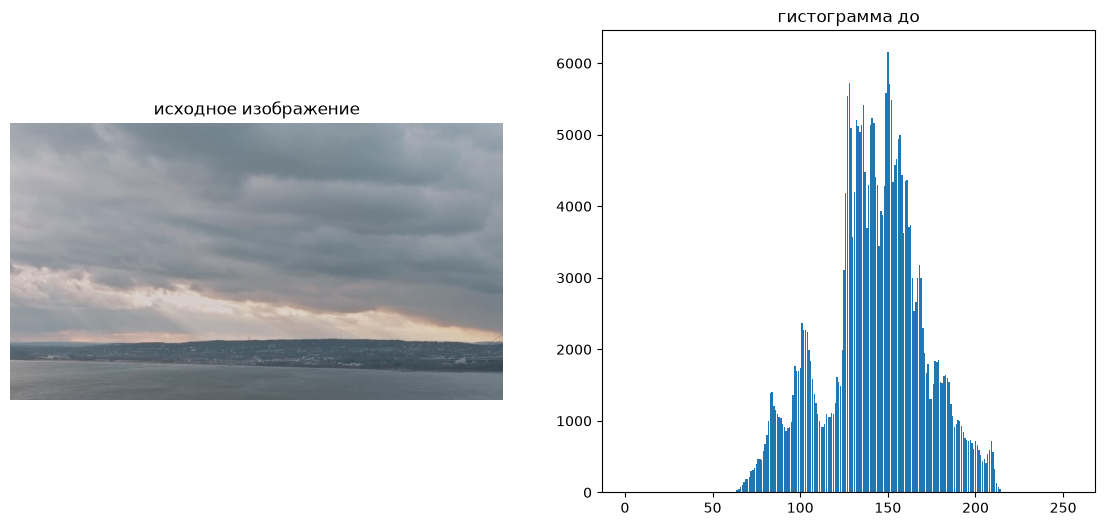

диапазон яркости: [52; 215], std 28.2


In [268]:
flat_path = str(BASE_DIR / "image2.jpg")

flat_image = cv2.imread(flat_path, cv2.IMREAD_COLOR_RGB)
if flat_image is None:
    raise FileNotFoundError(flat_path)


def hist_of(img):
    """Гистограмма яркости (Y)."""
    y = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    return np.bincount(y.ravel(), minlength=256)


y_flat = cv2.cvtColor(flat_image, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.imshow(flat_image)
plt.title("исходное изображение")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.bar(np.arange(256), hist_of(flat_image))
plt.title("гистограмма до")
plt.show()

print(f"диапазон яркости: [{y_flat.min()}; {y_flat.max()}], std {y_flat.std():.1f}")


### 3.1. Нормализация гистограммы

Линейно растягиваем диапазон яркостей на `[0, 255]`.


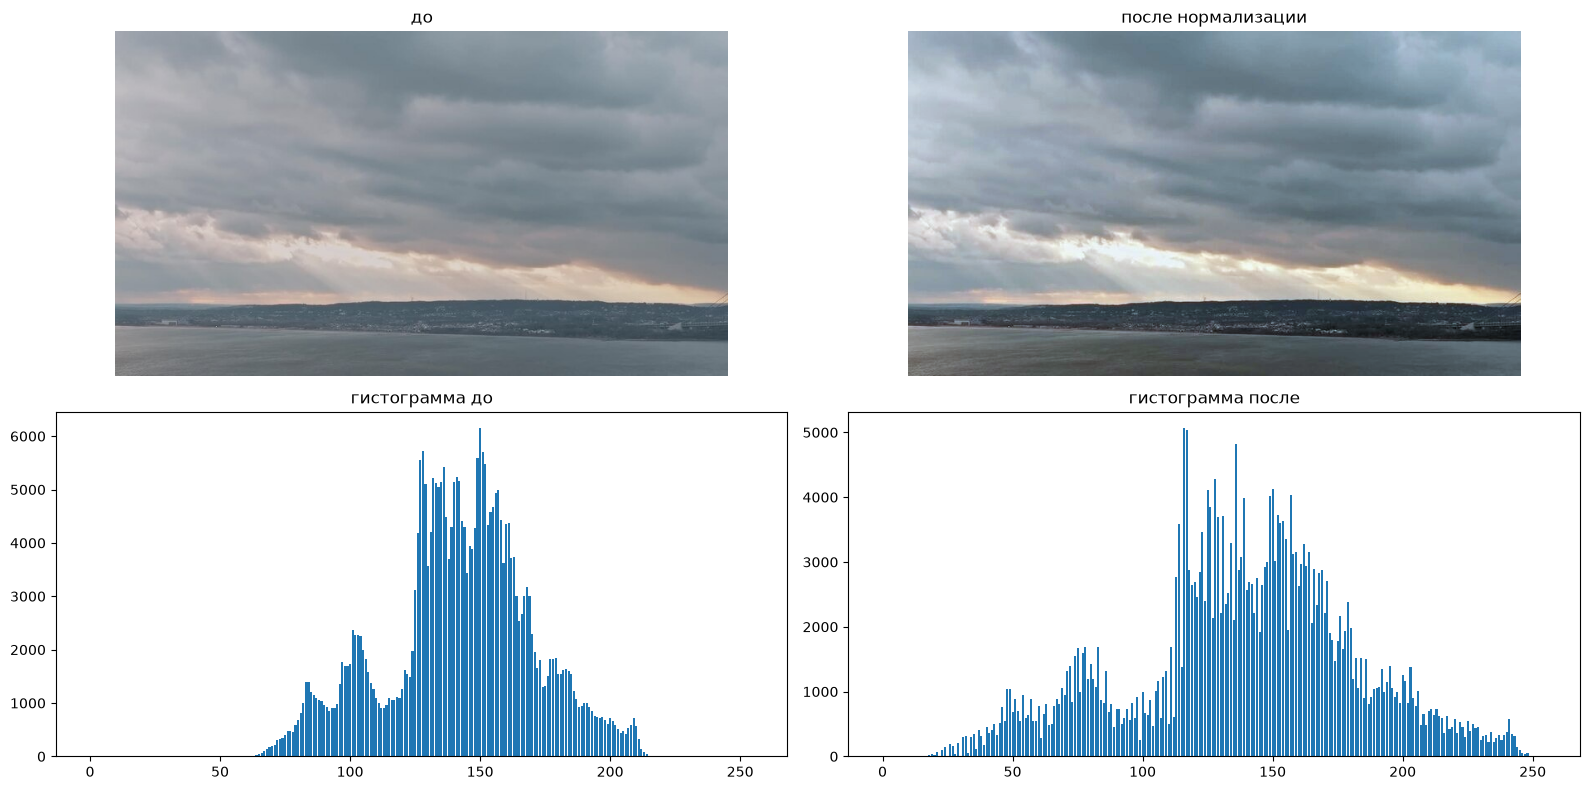

каналы до    : [41 55 64] -> [230 214 209]
каналы после : [0 0 0] -> [255 255 255]


In [269]:
def normalize_hist(img):
    """Покомпонентное растяжение: [min, max] каждого канала -> [0, 255]."""
    luts = []
    for i in range(3):
        lo, hi = img[:, :, i].min(), img[:, :, i].max()
        luts.append(build_lut(lambda v, lo=lo, hi=hi: (v - lo) * 255.0 / max(hi - lo, 1e-6)))
    return apply_luts(img, luts)


normalized = normalize_hist(flat_image)

plt.figure(figsize=(16, 8))
plt.subplot(2, 2, 1)
plt.imshow(flat_image)
plt.title("до")
plt.axis("off")
plt.subplot(2, 2, 2)
plt.imshow(normalized)
plt.title("после нормализации")
plt.axis("off")
plt.subplot(2, 2, 3)
plt.bar(np.arange(256), hist_of(flat_image))
plt.title("гистограмма до")
plt.subplot(2, 2, 4)
plt.bar(np.arange(256), hist_of(normalized))
plt.title("гистограмма после")
plt.tight_layout()
plt.show()

print("каналы до    :", flat_image.reshape(-1, 3).min(axis=0), "->", flat_image.reshape(-1, 3).max(axis=0))
print("каналы после :", normalized.reshape(-1, 3).min(axis=0), "->", normalized.reshape(-1, 3).max(axis=0))


### 3.2. Эквализация гистограммы

Алгоритм из лекции (слайд 38), один в один:

1. построить гистограмму `h[i]`;
2. нормировать: `h[i] = h[i] / (W * H)`;
3. накопить: `h[i] = h[i-1] + h[i]`;
4. заменить яркости: `Pixels[i, j] = 255 * h[round(255 * Pixels[i, j])]`.

Эквализуем яркость (`Y` в `YCrCb`), чтобы не уехал цвет.

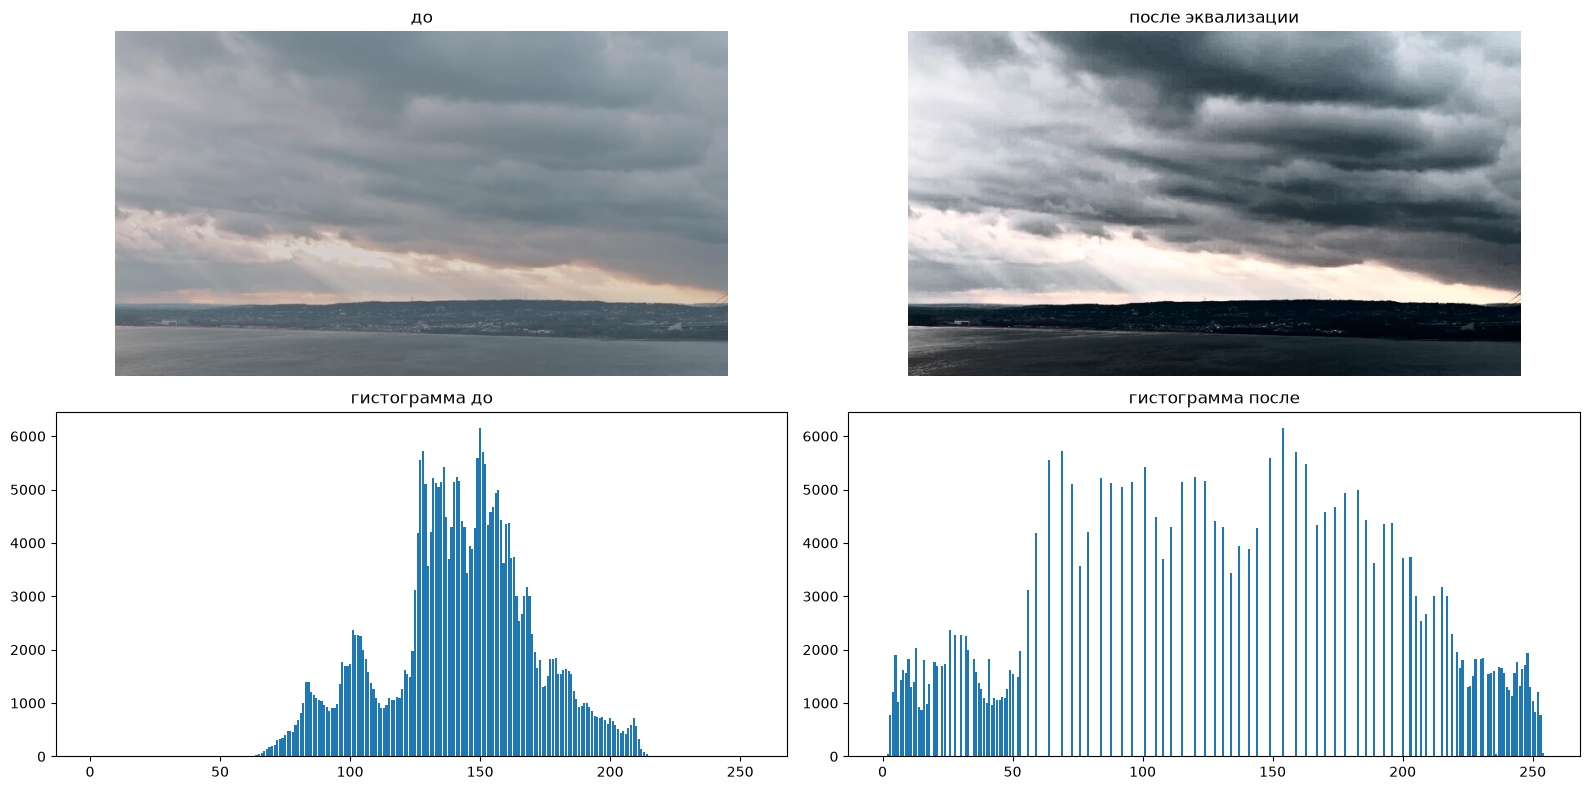

std яркости: 28.2 -> 73.4
занято уровней: 160 -> 123
расхождение с cv2.equalizeHist: максимум 6 уровня (переход YCrCb -> RGB округляет канал Y)


In [270]:
def equalize(img):
    """Эквализация гистограммы по алгоритму из лекции (слайд 38)."""
    ycc = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
    y = ycc[:, :, 0]
    height, width = y.shape
    k = 255

    # построение гистограммы
    h = np.bincount(y.ravel(), minlength=k + 1).astype(np.float64)

    # нормирование гистограммы
    h = h / (width * height)

    # построение гистограммы с накоплением
    for i in range(1, k + 1):
        h[i] = h[i - 1] + h[i]

    # равномерное распределение значений
    lookup = np.round(k * h).clip(0, k).astype(np.uint8)
    ycc[:, :, 0] = lookup[y]

    return cv2.cvtColor(ycc, cv2.COLOR_YCrCb2RGB)

equalized = equalize(flat_image)

plt.figure(figsize=(16, 8))
plt.subplot(2, 2, 1)
plt.imshow(flat_image)
plt.title("до")
plt.axis("off")
plt.subplot(2, 2, 2)
plt.imshow(equalized)
plt.title("после эквализации")
plt.axis("off")
plt.subplot(2, 2, 3)
plt.bar(np.arange(256), hist_of(flat_image))
plt.title("гистограмма до")
plt.subplot(2, 2, 4)
plt.bar(np.arange(256), hist_of(equalized))
plt.title("гистограмма после")
plt.tight_layout()
plt.show()

y_eq = cv2.cvtColor(equalized, cv2.COLOR_RGB2GRAY)
y_ref = cv2.equalizeHist(np.ascontiguousarray(y_flat))
max_diff = int(np.abs(y_eq.astype(int) - y_ref.astype(int)).max())

print(f"std яркости: {y_flat.std():.1f} -> {y_eq.std():.1f}")
print("занято уровней:", len(np.unique(y_flat)), "->", len(np.unique(y_eq)))
print(f"расхождение с cv2.equalizeHist: максимум {max_diff} уровня "
      f"(переход YCrCb -> RGB округляет канал Y)")


## 4. Сохранение результатов


In [271]:
results = [
    ("original",            image),
    ("corrected_reference", corrected_ref),
    ("corrected_gray_world", corrected_gw),
    ("corrected_lut",       corrected_lut),
    ("tone_piecewise",      toned_piecewise),
    ("tone_spline",         toned_spline),
    ("flat_original",       flat_image),
    ("hist_normalized",     normalized),
    ("hist_equalized",      equalized),
]

for name, img in results:
    cv2.imwrite(str(OUT_DIR / f"{name}.png"), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))

print(f"Saved to {OUT_DIR.resolve()}")


Saved to /Users/vladimirafonchenkov/Projects/comp_vision/lab2/outputs
